In [521]:
import pandas as pd
from sqlalchemy import create_engine
import time
import requests
import pandas as pd
import numpy as np
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL



DB_CONFIG = {
    "host": "aws-0-eu-west-1.pooler.supabase.com",
    "port": 6543,
    "database": "postgres",
    "user": "postgres.palaoxigjbvbrgdnbstd",
    "password": "@ghZ2XjxsdL_*m*"
}



url = URL.create(
    drivername="postgresql+psycopg2",
    username=DB_CONFIG["user"],
    password=DB_CONFIG["password"],
    host=DB_CONFIG["host"],
    port=DB_CONFIG["port"],
    database=DB_CONFIG["database"]
)

engine = create_engine(url)

In [522]:
import pandas as pd


#demo istat
query_demo = """
select * from storica_demo
"""
query_meteo = """
select * from como_weather_1980_2025
union select * from sondrio_weather_1980_2025
union select * from lecco_weather_1980_2020
union select * from bergamo_weather_1980_2025
union select * from genova_weather_1980_2025
union select * from imperia_weather_1980_2025
union select * from lucca_meteo_1980_2025
union select * from la_spezia_weather_1980_2025
union select * from massa_meteo_1980_2025
union select * from savona_weather_1980_2025
union select * from rovigo_meteo_1980_2025
union select * from verona_meteo_1980_2025
union select * from vicenza_meteo_1980_2025
union select * from udine_meteo_1980_2025
union select * from aosta_weather_1980_2025
union select * from belluno_meteo_1980_2025
union select * from padova_meteo_1980_2025
union select * from treviso_meteo_1980_2025
"""

query_anagrafica_comuni = """
select * from anagrafica_comuni
"""
query_centri = """
select * from accessibilita_centri_urbani"""

centri_urbani = pd.read_sql(query_centri, engine)

demo = pd.read_sql(query_demo, engine)
meteo = pd.read_sql(query_meteo, engine)
anag = pd.read_sql(query_anagrafica_comuni, engine)



## dati sul rischio idrogeologico

In [523]:
idrogeo = pd.read_csv('Indicatori_Intero_territorio_nazionale.csv', sep=',', na_values=[''], quotechar='"')

/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_65320/2155932705.py:1: DtypeWarning: Columns (21,32,48,51,97,98,99,100,101,112,115,116,117,118,122,142,145,146,147,154,155,156,157,158,159,160,161,162,184,186,190,191,192,193,202,205,208,214,217,220,223,226,392,394,395,396) have mixed types. Specify dtype option on import or set low_memory=False.
  idrogeo = pd.read_csv('Indicatori_Intero_territorio_nazionale.csv', sep=',', na_values=[''], quotechar='"')


In [524]:
df_ID = idrogeo[[
    "DZCOM",
    "PROCOM",
    "POP_2018",
    "POP_2011",
    "VAR_PERC",
    "VECCH",
    "POP_ANZ",
    "DENSPOP",
    "PAI_POPAA_P",
    "PAI_POPP3_P4_P",
    "PAI_AREAAA_P",
    "PAI_AREAP3_P4_P",
    "COMUNE_MONTANO",
    "ZONA_ALT"
]].copy()

In [525]:
'''
    "DZCOM": "Nome del comune",
    "PROCOM": "Codice ISTAT del comune",
    "POP_2018": "Popolazione residente al 2018",
    "POP_2011": "Popolazione residente al 2011",
    "VAR_PERC": "Variazione percentuale della popolazione tra 2011 e 2018",
    "VECCH": "Indice di vecchiaia",
    "POP_ANZ": "Popolazione anziana residente",
    "DENSPOP": "Densità della popolazione (abitanti per km²)",
    "PAI_POPAA_P": "Percentuale della popolazione residente in aree a pericolosità idrogeologica",
    "PAI_POPP3_P4_P": "Percentuale della popolazione residente nelle aree a pericolosità elevata e molto elevata (P3 + P4)",
    "PAI_AREAAA_P": "Percentuale della superficie comunale classificata a rischio idrogeologico",
    "PAI_AREAP3_P4_P": "Percentuale della superficie comunale classificata a pericolosità elevata e molto elevata (P3 + P4)",
    "COMUNE_MONTANO": "Indicatore che identifica se il comune è classificato come montano",
    "ZONA_ALT": "Classe altimetrica del comune"
'''

'\n    "DZCOM": "Nome del comune",\n    "PROCOM": "Codice ISTAT del comune",\n    "POP_2018": "Popolazione residente al 2018",\n    "POP_2011": "Popolazione residente al 2011",\n    "VAR_PERC": "Variazione percentuale della popolazione tra 2011 e 2018",\n    "VECCH": "Indice di vecchiaia",\n    "POP_ANZ": "Popolazione anziana residente",\n    "DENSPOP": "Densità della popolazione (abitanti per km²)",\n    "PAI_POPAA_P": "Percentuale della popolazione residente in aree a pericolosità idrogeologica",\n    "PAI_POPP3_P4_P": "Percentuale della popolazione residente nelle aree a pericolosità elevata e molto elevata (P3 + P4)",\n    "PAI_AREAAA_P": "Percentuale della superficie comunale classificata a rischio idrogeologico",\n    "PAI_AREAP3_P4_P": "Percentuale della superficie comunale classificata a pericolosità elevata e molto elevata (P3 + P4)",\n    "COMUNE_MONTANO": "Indicatore che identifica se il comune è classificato come montano",\n    "ZONA_ALT": "Classe altimetrica del comune"\n'

In [526]:
df_ID.head()


,DZCOM,PROCOM,POP_2018,POP_2011,VAR_PERC,VECCH,POP_ANZ,DENSPOP,PAI_POPAA_P,PAI_POPP3_P4_P,PAI_AREAAA_P,PAI_AREAP3_P4_P,COMUNE_MONTANO,ZONA_ALT
0,Altino,69001,3104,2844,"9,142053445850914","132,72357723577235","6,701030927835052","202,4735166727548",0,29984,0,"581,302300512",1,3
1,Archi,69002,2136,2280,"-6,315789473684211","233,0739299610895","9,597378277153558","74,82974131890923",0,29984,0,"581,302300512",3,3
2,Ari,69003,1148,1161,"-1,119724375538329","306,55737704918033","9,843205574912892","100,77512574944916",0,29984,0,"581,302300512",1,4
3,Arielli,69004,1129,1142,"-1,138353765323993","250,3875968992248","9,21169176262179","96,35654481987555",0,29984,0,"581,302300512",1,4
4,Atessa,69005,10580,10767,"-1,736788334726479","168,4536082474227","7,381852551984877","95,33421038404009",0,29984,0,"581,302300512",2,4


In [527]:
df_ID["comune_norm"] = (
    df_ID["DZCOM"]
    .str.upper()
    .str.strip()
)

In [528]:
df_ID["comune_norm"] = (df_ID["comune_norm"].
                        str.replace(r"\(.*?\)", "", regex=True)
    .str.strip())

In [529]:
meteo["comune_norm"] = (
    meteo["comune"]
    .str.upper()
    .str.strip()
)

In [530]:
meteo_year = (
    meteo
    .groupby(
        ["comune", "year"],
        as_index=False
    )
    .agg(
        temp_mean=("temperature_mean", "mean"),
        rain_sum=("rain_sum", "sum"),
        snow_sum=("snowfall_sum", "sum")
    )
)
##std tempreratura e pioggia
meteo_var = (
    meteo
    .groupby(
        ["comune", "year"],
        as_index=False
    )
    .agg(
        temp_sd=("temperature_mean", "std"),
        rain_sd=("rain_sum", "std")
    )
)

In [531]:
meteo_year = meteo_year.merge(
    meteo_var,
    on=["comune", "year"]
)
##numero mesi con neve
snow_months = (
    meteo
    .assign(
        snow_month=lambda x:
        (x["snowfall_sum"] > 0).astype(int)
    )
    .groupby(
        ["comune", "year"],
        as_index=False
    )
    .agg(
        n_snow_months=("snow_month", "sum")
    )
)
meteo_year = meteo_year.merge(
    snow_months,
    on=["comune", "year"]
)

In [532]:
##temp media invernale
winter = meteo[
    meteo["month"].isin([12, 1, 2])
]

winter_temp = (
    winter
    .groupby(
        ["comune", "year"],
        as_index=False
    )
    .agg(
        winter_temp_mean=("temperature_mean", "mean")
    )
)
#pioggia estrema: mesi sopra il 90 percentile
threshold = meteo["rain_sum"].quantile(0.90)

meteo["heavy_rain"] = (
        meteo["rain_sum"] > threshold
).astype(int)

In [533]:
heavy_rain = (
    meteo
    .groupby(
        ["comune", "year"],
        as_index=False
    )
    .agg(
        n_heavy_rain_months=("heavy_rain", "sum")
    )
)
meteo_year = (
    meteo_year
    .merge(
        winter_temp,
        on=["comune", "year"],
        how="left"
    )
    .merge(
        heavy_rain,
        on=["comune", "year"],
        how="left"
    )
)

In [534]:
meteo_year = (
    meteo_year
    .sort_values(
        ["comune", "year"]
    )
)
##aggiungo la media rolling degli ultimi 3 anni
meteo_year["snow_3y"] = (
    meteo_year
    .groupby("comune")
    ["snow_sum"]
    .transform(
        lambda x:
        x.rolling(
            3,
            min_periods=1
        ).mean()
    )
)

In [535]:
##trend neve, temp, pioggia con regressione lineare: prendo la slope di y = beta*x + alfa
import numpy as np
import pandas as pd


def compute_trend(group, var):
    x = group["year"].values
    y = group[var].values

    if len(group) < 2:
        return np.nan

    # regressione lineare
    beta = np.polyfit(x, y, 1)[0]
    return beta


snow_trend = (
    meteo_year
    .groupby("comune")
    .apply(lambda g: compute_trend(g, "snow_sum"))
    .reset_index()
)

snow_trend.columns = ["comune", "snow_trend"]
temp_trend = (
    meteo_year
    .groupby("comune")
    .apply(lambda g: compute_trend(g, "temp_mean"))
    .reset_index()
)

temp_trend.columns = ["comune", "temp_trend"]
rain_trend = (
    meteo_year
    .groupby("comune")
    .apply(lambda g: compute_trend(g, "rain_sum"))
    .reset_index()
)

rain_trend.columns = ["comune", "rain_trend"]
meteo_trends = (
    snow_trend
    .merge(temp_trend, on="comune")
    .merge(rain_trend, on="comune")
)

meteo_year = meteo_year.rename(columns={"year": "anno"})
#uso solo il periodo 2014-2026
start_year = 1980
end_year = 2026


meteo_year = meteo_year[(meteo_year["anno"] >= start_year) & (meteo_year["anno"] <= end_year)]
demo = demo[(demo["anno"] >= start_year) & (demo["anno"] <= end_year)]

/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_65320/3765195408.py:21: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: compute_trend(g, "snow_sum"))
/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_65320/3765195408.py:29: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: compute_trend(g, "temp_mean"))
/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_65320/37

In [536]:
meteo_year["comune_norm"] = meteo_year["comune"].str.upper().str.strip()

## dato su impianti dismessi

In [537]:
impianti_dismessi = pd.read_csv("impianti_dismessi.csv")

impianti_dismessi["comune_norm"] = (
    impianti_dismessi["comune"]
    .str.upper()
    .str.strip()
)

# casi tipo "Macugnaga (VCO)"
impianti_dismessi["comune_norm"] = (
    impianti_dismessi["comune_norm"]
    .str.replace(r"\(.*?\)", "", regex=True)
    .str.strip()
)

In [538]:
mapping = {
    "DESERTETTO, LOC. DI VALDIERI": "VALDIERI",
    "COLLE DEL SOMMEILLER - BARDONECCHIA": "BARDONECCHIA",
    "OGGEBIO": "OGGEBBIO",
    "MUCRONE": np.nan,
}

impianti_dismessi["comune_norm"] = (
    impianti_dismessi["comune_norm"]
    .replace(mapping)
)

In [539]:
impianti_count = (
    impianti_dismessi.groupby("comune_norm")
    .size()
    .reset_index(name="n_impianti_dismessi")
)

In [540]:
impianti_dismessi.head()

,Unnamed: 0,id,nome,regione,provincia,comune,quota,tipologia,anno_costruzione,anno_dismissione,comune_norm
0,0,1,BASILICATA 2024 2 2025 2 2026 3 Valle d’Aosta ...,Valle d'Aosta,AO,Challand-Saint Anselme,730 s.l.m. m,uno skilift,inizio anni ‘80,fine anni ‘90,CHALLAND-SAINT ANSELME
1,1,2,Impianto - Aymavilles,Valle d'Aosta,AO,Aymavilles,1400 m s.l.m - 1650 m s.l.m,uno skilift,anni ‘60,1973,AYMAVILLES
2,2,3,Impianto - Valtournenche,Valle d'Aosta,AO,Valtournenche,2400 m s.l.m. - 3.486 m s.l.m.,Funivia e annesso tunnel di cemento,1952,1993,VALTOURNENCHE
3,3,4,Impianto - La Magdaleine,Valle d'Aosta,AO,La Magdaleine,1660 m s.l.m. - 1820 m s.l.m.,uno skilift,1952,1993,LA MAGDALEINE
4,4,5,Impianto - Valtournenche,Valle d'Aosta,AO,Valtournenche,2900 m s.l.m circa,"quattro funivie, uno skilift",anni ‘60,inizio anni ’90,VALTOURNENCHE


In [541]:
print(anag.shape)

(7894, 42)


## dati anagrafici comuni

In [542]:
anag.columns

Index(['codice_regione',
       'Codice dell'Unità territoriale sovracomunale \n(valida a fini s',
       'codice_provincia', 'Progressivo del Comune (2)', 'codice_comune',
       'Denominazione (Italiana e straniera)', 'Denominazione in italiano',
       'Denominazione altra lingua', 'Codice Ripartizione Geografica',
       'Ripartizione geografica', 'Denominazione Regione',
       'Denominazione_province',
       'Tipologia di Unità territoriale sovracomunale ',
       'Flag Comune capoluogo di Provincia/Città metropolitana/libero ',
       'Sigla automobilistica', 'Codice Comune formato numerico',
       'Codice Comune numerico con 107 Province (dal 2017 al 2025)',
       'Codice Comune numerico con 110 Province (dal 2010 al 2016)',
       'Codice Comune numerico con 107 Province (dal 2006 al 2009)',
       'Codice Comune numerico con 103 Province (dal 1995 al 2005)',
       'Codice Catastale del Comune', 'Codice NUTS1 2021',
       'Codice NUTS2 2021 (3) ', 'Codice NUTS3 2021', 'Co

In [543]:
anag = anag[['Denominazione in italiano','0-299 (%)', '300-599 (%)', '600-899 (%)', '900-1199 (%)',
       '1200-1499 (%)', '1500-1999 (%)', '2000-2499 (%)', '>=2500 (%)',
       'comune_montano', 'Fascia_Prevalente', 'Classificazione_Finale','latitudine','longitudine']]

# zona altimetrica media pesata

In [544]:
## creo una appartenenza media per fascia con media pesata
mapping = {
    "0-299 (%)": 1,
    "300-599 (%)": 2,
    "600-899 (%)": 3,
    "900-1199 (%)": 4,
    "1200-1499 (%)": 5,
    "1500-1999 (%)": 6,
    "2000-2499 (%)": 7,
    ">=2500 (%)": 8
}

anag["zona_altimetrica_media"] = sum(
    anag[col] * mapping[col]/100
    for col in mapping
)

In [545]:
anag.head()

,Denominazione in italiano,0-299 (%),300-599 (%),600-899 (%),900-1199 (%),1200-1499 (%),1500-1999 (%),2000-2499 (%),>=2500 (%),comune_montano,Fascia_Prevalente,Classificazione_Finale,latitudine,longitudine,zona_altimetrica_media
0,Airasca,100.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0,0-299 (%),Collinare,4.975382e+06,380324.101871,1.000000
1,Albiano d'Ivrea,100.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0,0-299 (%),Collinare,5.031462e+06,417396.987982,1.000000
2,Andezeno,78.265976,21.734024,0.0,0.0,0.0,0.0,0.0,0.0,0,0-299 (%),Collinare,4.987583e+06,410699.814585,1.217340
3,Arignano,56.668300,43.331700,0.0,0.0,0.0,0.0,0.0,0.0,0,0-299 (%),Collinare,4.987735e+06,413271.450438,1.433317
4,Azeglio,98.388652,1.611348,0.0,0.0,0.0,0.0,0.0,0.0,0,0-299 (%),Collinare,5.030384e+06,421235.105218,1.016113


In [546]:


demo["comune_norm"] = (
    demo["comune_norm"]
    .str.upper()
    .str.strip()
)



anag["comune_norm"] = ( anag["Denominazione in italiano"]
    .str.upper()
    .str.strip())

centri_urbani["comune_norm"] = ( centri_urbani["comune"]
    .str.upper()
    .str.strip())

In [547]:
centri_urbani.head()

,regione,provincia,comune,popolazione,hub_15min_5000ab,hub_5000_vicino,hub_5000_pop,tempo_hub_5000,comune_norm
0,Lombardia,VA,Agra,381.0,1,Luino,14125.0,14.0,AGRA
1,Lombardia,VA,Albizzate,5184.0,8,Albizzate,5184.0,0.0,ALBIZZATE
2,Lombardia,VA,Angera,5329.0,2,Angera,5329.0,0.0,ANGERA
3,Lombardia,VA,Arcisate,9916.0,2,Arcisate,9916.0,0.0,ARCISATE
4,Lombardia,VA,Arsago Seprio,4735.0,11,Casorate Sempione,5596.0,5.0,ARSAGO SEPRIO


In [548]:
###per comuni con slash e doppia lingua
def clean_comune(x):
    return (
        x.upper()
         .split("/")[0]
         .strip()
    )

In [549]:
centri_urbani = centri_urbani.drop_duplicates(subset=["comune"])

In [550]:
centri_urbani = centri_urbani.dropna()

In [551]:
centri_urbani.drop('comune', axis=1, inplace=True)

## faccio merge dei vari dataset

In [552]:
df = (

        demo

    .merge(
        anag,
        on=["comune_norm"],
        how="inner"
    )
  .merge(centri_urbani, on=["comune_norm"], how="inner")
    .merge(df_ID, on=["comune_norm"], how="inner")
    .merge(
        meteo_year,
        on=["comune_norm", "anno"],
        how="inner"
    )
    .merge(impianti_dismessi, on=["comune_norm"], how="left")

)

In [553]:
df.columns

Index(['id_demo', 'comune_x', 'provincia_x', 'anno', 'm_anno_0', 'f_anno_0',
       't_anno_0', 'm_0_5_prima_infanzia', 'm_6_11_infanzia',
       'm_12_17_adolescenza', 'm_18_24_giovani_adulti',
       'm_25_34_adulti_giovani', 'm_35_44_adulti', 'm_45_54_adulti_maturi',
       'm_55_64_pre_senior', 'm_65_74_senior', 'm_75_e_oltre_anziani',
       'f_0_5_prima_infanzia', 'f_6_11_infanzia', 'f_12_17_adolescenza',
       'f_18_24_giovani_adulti', 'f_25_34_adulti_giovani', 'f_35_44_adulti',
       'f_45_54_adulti_maturi', 'f_55_64_pre_senior', 'f_65_74_senior',
       'f_75_e_oltre_anziani', 't_0_5_prima_infanzia', 't_6_11_infanzia',
       't_12_17_adolescenza', 't_18_24_giovani_adulti',
       't_25_34_adulti_giovani', 't_35_44_adulti', 't_45_54_adulti_maturi',
       't_55_64_pre_senior', 't_65_74_senior', 't_75_e_oltre_anziani',
       'totale_generale', 'delta_pct_acumulado', 'codice_comune',
       'codice_comune_normalizzato', 'comune_norm', 'id_x',
       'Denominazione in italiano

# differenza meteo rispetto a anni 80

In [554]:
##aggiungo l'informazione del meteo anni 80
#clima medio anni 80
climate_80 = (
    meteo[
        meteo["year"].between(1980, 1990)
    ]
    .groupby("comune_norm", as_index=False)
    .agg(
        temp80=("temperature_mean", "mean"),
        snow80=("snowfall_sum", "mean"),
        rain80=("rain_sum", "mean")
    )
)
climate_80

,comune_norm,temp80,snow80,rain80
0,ABANO TERME,12.408194,0.746136,67.427273
1,ABBADIA LARIANA,10.123348,12.319470,124.484848
2,ADRIA,13.615281,0.531894,62.190909
3,AFFI,12.773095,2.087273,70.621212
4,AGNA,13.292609,0.692045,69.173485
...,...,...,...,...
1304,ZOPPÈ DI CADORE,2.564071,33.417045,92.852273
1305,ZOVENCEDO,11.504672,2.727348,81.748485
1306,ZUCCARELLO,13.413868,5.198561,67.504545
1307,ZUGLIANO,11.261644,6.832424,110.340152


In [555]:
#clima medio recente
climate_now = (
    meteo[
        meteo["year"].between(2015, 2025)
    ]
    .groupby("comune_norm", as_index=False)
    .agg(
        temp_now=("temperature_mean", "mean"),
        snow_now=("snowfall_sum", "mean"),
        rain_now=("rain_sum", "mean")
    )
)
climate_now

,comune_norm,temp_now,snow_now,rain_now
0,ABANO TERME,14.408415,0.516515,77.356061
1,ABBADIA LARIANA,12.120831,5.581579,134.094737
2,ADRARA SAN MARTINO,12.267472,1.627213,123.455738
3,ADRARA SAN ROCCO,9.693519,2.565902,126.449180
4,ADRIA,14.779028,0.220606,75.028030
...,...,...,...,...
1547,ZOPPÈ DI CADORE,3.659181,26.274924,88.628030
1548,ZOVENCEDO,13.939210,0.828333,91.496970
1549,ZUCCARELLO,14.995826,1.343788,75.284848
1550,ZUGLIANO,13.161140,1.414318,102.727273


In [556]:
##cambiamento climatico anni 80 ad anni 2015-2025
climate_change = (
    climate_80
    .merge(climate_now,on="comune_norm")
)

climate_change["delta_temp"] = (
    climate_change["temp_now"]
    - climate_change["temp80"]
)

climate_change["delta_snow"] = (
    climate_change["snow_now"]
    - climate_change["snow80"]
)

climate_change["delta_rain"] = (
    climate_change["rain_now"]
    - climate_change["rain80"]
)

In [557]:
df.head()

,id_demo,comune_x,provincia_x,anno,m_anno_0,f_anno_0,t_anno_0,m_0_5_prima_infanzia,m_6_11_infanzia,m_12_17_adolescenza,...,Unnamed: 0,id_y,nome,regione_y,provincia,comune,quota,tipologia,anno_costruzione,anno_dismissione
0,014064_1997,Tartano,Sondrio,1997,1,0,1,7,2,9,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,014064_1996,Tartano,Sondrio,1996,4,4,8,9,1,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,014064_1995,Tartano,Sondrio,1995,0,0,0,5,1,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,014064_1994,Tartano,Sondrio,1994,2,1,3,6,5,7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,014064_1993,Tartano,Sondrio,1993,1,0,1,5,6,9,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [558]:
print(df.shape)
print(df["comune_norm"].nunique())
print(df["anno"].min(), df["anno"].max())

(46429, 99)
1539
1992 2025


In [559]:
df.duplicated(["comune_norm", "anno","provincia_x"]).sum() #check dei duplicati

np.int64(833)

In [560]:
dup = df[df.duplicated(["comune_norm", "anno","provincia_x"], keep=False)]

dup.sort_values(["comune_norm", "anno","provincia_x"])

,id_demo,comune_x,provincia_x,anno,m_anno_0,f_anno_0,t_anno_0,m_0_5_prima_infanzia,m_6_11_infanzia,m_12_17_adolescenza,...,Unnamed: 0,id_y,nome,regione_y,provincia,comune,quota,tipologia,anno_costruzione,anno_dismissione
28747,025038_1992,Pieve d'Alpago,Belluno,1992,9,3,12,39,52,67,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28748,025041_1992,Puos d'Alpago,Belluno,1992,8,6,14,62,54,83,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28764,025020_1992,Farra d'Alpago,Belluno,1992,12,11,23,80,70,93,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28746,025038_1993,Pieve d'Alpago,Belluno,1993,6,5,11,38,46,66,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28750,025041_1993,Puos d'Alpago,Belluno,1993,4,8,12,56,56,78,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28400,097087_1999,Verderio Inferiore,Lecco,1999,14,9,23,78,67,79,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28391,097088_2000,Verderio Superiore,Lecco,2000,22,9,31,98,79,57,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28401,097087_2000,Verderio Inferiore,Lecco,2000,12,21,33,84,67,79,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28392,097088_2001,Verderio Superiore,Lecco,2001,17,21,38,108,84,54,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [561]:
dup = df[df.duplicated(["comune_norm", "anno","provincia_x"], keep=False)]
dup.sort_values(["comune_norm", "anno","provincia_x"])

,id_demo,comune_x,provincia_x,anno,m_anno_0,f_anno_0,t_anno_0,m_0_5_prima_infanzia,m_6_11_infanzia,m_12_17_adolescenza,...,Unnamed: 0,id_y,nome,regione_y,provincia,comune,quota,tipologia,anno_costruzione,anno_dismissione
28747,025038_1992,Pieve d'Alpago,Belluno,1992,9,3,12,39,52,67,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28748,025041_1992,Puos d'Alpago,Belluno,1992,8,6,14,62,54,83,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28764,025020_1992,Farra d'Alpago,Belluno,1992,12,11,23,80,70,93,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28746,025038_1993,Pieve d'Alpago,Belluno,1993,6,5,11,38,46,66,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28750,025041_1993,Puos d'Alpago,Belluno,1993,4,8,12,56,56,78,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28400,097087_1999,Verderio Inferiore,Lecco,1999,14,9,23,78,67,79,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28391,097088_2000,Verderio Superiore,Lecco,2000,22,9,31,98,79,57,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28401,097087_2000,Verderio Inferiore,Lecco,2000,12,21,33,84,67,79,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28392,097088_2001,Verderio Superiore,Lecco,2001,17,21,38,108,84,54,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [562]:
df = df.sort_values(["comune_norm", "anno"]) #ordino per comune/anno

In [563]:
#crescita annuale: calcola la variazione percentuale annuale rispetto all'anno precedente
df["growth_rate"] = (
    df.groupby("comune_norm")["totale_generale"]
    .pct_change()
)

In [564]:
MIN_POP_BASE = 1

pop1992 = (
    df[df["anno"] == 1992][["comune_norm", "totale_generale"]]
    .rename(columns={"totale_generale": "pop1992"})
)

df = df.merge(pop1992, on="comune_norm", how="left")

df["growth_since_1992"] = np.where(
    df["pop1992"] >= MIN_POP_BASE,
    (df["totale_generale"] - df["pop1992"]) / df["pop1992"],
    0
)

In [565]:
pop1992

,comune_norm,pop1992
13917,ABANO TERME,17756
25174,ABBADIA LARIANA,2997
17322,ADRIA,21216
2006,AFFI,1468
13984,AGNA,3095
...,...,...
10676,ZOPPÈ DI CADORE,308
8704,ZOVENCEDO,723
35990,ZUCCARELLO,299
8767,ZUGLIANO,5503


In [566]:
df.head()

,id_demo,comune_x,provincia_x,anno,m_anno_0,f_anno_0,t_anno_0,m_0_5_prima_infanzia,m_6_11_infanzia,m_12_17_adolescenza,...,regione_y,provincia,comune,quota,tipologia,anno_costruzione,anno_dismissione,growth_rate,pop1992,growth_since_1992
0,028001_1992,Abano Terme,Padova,1992,69,77,146,409,472,698,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17756.0,0.000000
1,028001_1993,Abano Terme,Padova,1993,62,78,140,402,469,634,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.005632,17756.0,0.005632
2,028001_1994,Abano Terme,Padova,1994,77,77,154,424,435,578,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.001120,17756.0,0.004506
3,028001_1995,Abano Terme,Padova,1995,76,64,140,432,430,547,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.007345,17756.0,0.011883
4,028001_1996,Abano Terme,Padova,1996,67,73,140,439,432,499,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.003506,17756.0,0.015431


## qui metto la soglia di spopolamento (qui 5%)

In [567]:
df["spopolamento"] = (df["growth_since_1992"] < -0.05).astype(int)
##variabili demo
df["anziani"] = df["t_65_74_senior"] + df["t_75_e_oltre_anziani"]

df["giovani"] = df["t_18_24_giovani_adulti"] + df["t_25_34_adulti_giovani"]

df["bambini"] = (
        df["t_0_5_prima_infanzia"] +
        df["t_6_11_infanzia"] +
        df["t_12_17_adolescenza"]
)

df["share_anziani"] = df["anziani"] / df["totale_generale"]
df["share_giovani"] = df["giovani"] / df["totale_generale"]
#df["indice_vecchiaia"] = df["anziani"] / df["bambini"]

In [568]:
target = df[df["anno"] == 2025]

target

,id_demo,comune_x,provincia_x,anno,m_anno_0,f_anno_0,t_anno_0,m_0_5_prima_infanzia,m_6_11_infanzia,m_12_17_adolescenza,...,anno_dismissione,growth_rate,pop1992,growth_since_1992,spopolamento,anziani,giovani,bambini,share_anziani,share_giovani
33,028001_2025,Abano Terme,Padova,2025,57,48,105,392,481,567,...,NaN,0.001517,17756.0,0.152512,0,5930,3212,2722,0.289777,0.156959
67,097001_2025,Abbadia Lariana,Lecco,2025,7,13,20,65,65,75,...,anni ‘80,-0.007217,2997.0,0.055722,0,846,532,412,0.267383,0.168142
73,016001_2025,Adrara San Martino,Bergamo,2025,5,6,11,45,69,72,...,NaN,0.017584,NaN,0.000000,0,418,462,345,0.190086,0.210095
79,016002_2025,Adrara San Rocco,Bergamo,2025,1,2,3,17,17,22,...,NaN,0.009913,NaN,0.000000,0,199,139,117,0.244172,0.170552
113,029001_2025,Adria,Rovigo,2025,37,50,87,293,412,491,...,NaN,0.012449,21216.0,-0.114489,1,5519,2847,2348,0.293767,0.151541
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51839,025069_2025,Zoppè di Cadore,Belluno,2025,1,0,1,1,0,1,...,NaN,-0.052632,308.0,-0.415584,1,76,25,8,0.422222,0.138889
51873,024121_2025,Zovencedo,Vicenza,2025,1,3,4,26,24,19,...,NaN,-0.004837,723.0,0.138313,0,186,142,121,0.226002,0.172539
51907,009069_2025,Zuccarello,Savona,2025,0,0,0,3,9,5,...,NaN,-0.017606,299.0,-0.066890,1,71,45,36,0.254480,0.161290
51941,024122_2025,Zugliano,Vicenza,2025,21,27,48,153,186,190,...,NaN,0.000145,5503.0,0.254043,0,1579,1259,1072,0.228807,0.182437


In [569]:
analysis_df = analysis_df = (
    target
    .merge(
        climate_change,
        left_on="comune_norm",
        right_on="comune_norm",
        how="inner"
    )
).copy()

In [570]:
analysis_df.columns

Index(['id_demo', 'comune_x', 'provincia_x', 'anno', 'm_anno_0', 'f_anno_0',
       't_anno_0', 'm_0_5_prima_infanzia', 'm_6_11_infanzia',
       'm_12_17_adolescenza',
       ...
       'share_giovani', 'temp80', 'snow80', 'rain80', 'temp_now', 'snow_now',
       'rain_now', 'delta_temp', 'delta_snow', 'delta_rain'],
      dtype='object', length=117)

# clustering

In [571]:
cluster_features = [


    "zona_altimetrica_media",
    "tempo_hub_5000",
    "hub_5000_pop",
    "PAI_POPP3_P4_P",
    'delta_temp',
    'delta_snow',
    'delta_rain'

]

In [572]:
import seaborn as sns
import matplotlib.pyplot as plt

In [573]:
analysis_df[cluster_features].dtypes

zona_altimetrica_media    float64
tempo_hub_5000            float64
hub_5000_pop              float64
PAI_POPP3_P4_P              int64
delta_temp                float64
delta_snow                float64
delta_rain                float64
dtype: object

In [574]:
analysis_df[cluster_features].head()

,zona_altimetrica_media,tempo_hub_5000,hub_5000_pop,PAI_POPP3_P4_P,delta_temp,delta_snow,delta_rain
0,1.000000,0.0,20464.0,323,2.000221,-0.229621,9.928788
1,2.562624,6.0,9928.0,5659,1.997483,-6.737891,9.609888
2,1.000000,0.0,18787.0,0,1.163746,-0.311288,12.837121
3,1.128359,4.0,5997.0,1168,1.441097,-1.360758,18.073485
4,1.000000,13.0,5200.0,323,1.360592,-0.360076,7.994697


In [575]:
analysis_df["DENSPOP"] = (
    analysis_df["DENSPOP"]
    .str.replace(",", ".", regex=False)
    .astype(float)
)

In [576]:
clustering_df = (
    analysis_df[
        [
            "comune_norm","growth_since_1992",
            "Denominazione in italiano",
            "latitudine",
            "longitudine",
            *cluster_features
        ]
    ]
    .groupby(["comune_norm", "Denominazione in italiano"], as_index=False)
    .mean(numeric_only=True)
).copy()

In [577]:
clustering_df.dtypes

comune_norm                   object
Denominazione in italiano     object
growth_since_1992            float64
latitudine                   float64
longitudine                  float64
zona_altimetrica_media       float64
tempo_hub_5000               float64
hub_5000_pop                 float64
PAI_POPP3_P4_P               float64
delta_temp                   float64
delta_snow                   float64
delta_rain                   float64
dtype: object

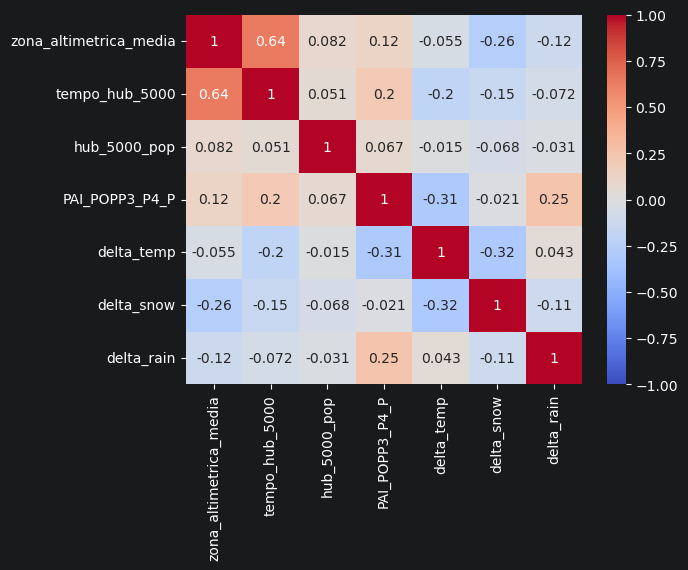

In [578]:
sns.heatmap(clustering_df[cluster_features].corr(method="pearson"), cmap="coolwarm", vmin=-1, vmax=1, annot=True)
plt.show()

In [579]:
from scipy.spatial.distance import pdist, cdist, squareform

In [580]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.stats import pearsonr, spearmanr

def get_sse(X, labels):
    sse = 0
    for l in np.unique(labels):
        c = np.mean(X[labels == l], axis=0)
        sse += np.sum(cdist(np.expand_dims(c, axis=0), X[labels == l]))
    return sse

def get_bss(X, labels):
    cluster_centers = list()
    for l in np.unique(labels):
        c = np.mean(X[labels == l], axis=0)
        cluster_centers.append(c)
    cluster_centers = np.array(cluster_centers)
    _, sizes = np.unique(labels, return_counts=True)
    m = np.mean(X, axis=0)
    bss = np.sum(sizes * cdist(np.expand_dims(m, axis=0), cluster_centers))
    return bss

def get_ideal_matrix(X, labels):
    P = np.ones((len(X), len(X)))
    for i in np.arange(len(X)):
        for j in np.arange(len(X)):
            if labels[i] == labels[j]:
                P[i, j] = 0.
    return P

def eval_clustering(X, D, labels):
   # corr = spearmanr(D.ravel(), get_ideal_matrix(X, labels).ravel())[0]
    sse = get_sse(X[labels != -1], labels[labels != -1])
    bss = get_bss(X[labels != -1], labels[labels != -1])
    silh = silhouette_score(X[labels != -1], labels[labels != -1])
    davis = davies_bouldin_score(X, labels)
    return (#corr,
            sse, bss, silh, davis)

### kmenas

In [581]:
X = clustering_df[cluster_features].copy()
X[:10]

,zona_altimetrica_media,tempo_hub_5000,hub_5000_pop,PAI_POPP3_P4_P,delta_temp,delta_snow,delta_rain
0,1.000000,0.0,20464.0,323.0,2.000221,-0.229621,9.928788
1,2.562624,6.0,9928.0,5659.0,1.997483,-6.737891,9.609888
2,1.000000,0.0,18787.0,0.0,1.163746,-0.311288,12.837121
3,1.128359,4.0,5997.0,1168.0,1.441097,-1.360758,18.073485
4,1.000000,13.0,5200.0,323.0,1.360592,-0.360076,7.994697
5,4.577790,25.0,10129.0,2677.0,1.435012,-7.493712,6.693939
6,1.000000,7.0,9183.0,2315.0,1.793853,-0.364848,10.478788
7,1.000000,9.0,13784.0,3284.0,1.738844,-1.756364,20.712879
8,1.866260,18.0,23024.0,8158.0,1.098811,-1.754242,13.983333
9,1.555359,7.0,6332.0,5659.0,1.911106,-3.113712,40.022927


In [582]:
from sklearn.preprocessing import StandardScaler

In [583]:


scaler = StandardScaler()
X = scaler.fit_transform(X)

In [584]:
X[:10] #controllo il vettore riscalato

array([[-0.82217667, -0.89271066,  0.28548348, -0.56279734,  0.36291166,
         0.65769608, -0.3533816 ],
       [ 0.12676983, -0.47785868, -0.19480268, -0.19908664,  0.35762184,
        -0.94155814, -0.37418693],
       [-0.82217667, -0.89271066,  0.20903702, -0.58481356, -1.25283561,
         0.63762842, -0.163639  ],
       [-0.74422734, -0.61614268, -0.37399828, -0.50520072, -0.71710016,
         0.37974592,  0.17798666],
       [-0.82217667,  0.00613529, -0.41032972, -0.56279734, -0.87260648,
         0.62563995, -0.47956365],
       [ 1.3505344 ,  0.83583923, -0.18564004, -0.40234475, -0.72885493,
        -1.12728347, -0.56442639],
       [-0.82217667, -0.40871669, -0.22876368, -0.42701928, -0.03571231,
         0.62446716, -0.31749905],
       [-0.82217667, -0.2704327 , -0.01902597, -0.36097062, -0.14196811,
         0.28253503,  0.35018339],
       [-0.29611646,  0.35184526,  0.40218171, -0.02875061, -1.37826594,
         0.28305626, -0.08885896],
       [-0.48491992, -0.4087

In [585]:
from sklearn.cluster import KMeans

In [586]:
D = pdist(X, metric="euclidean") #uso la distanza classica euclidea per calcolare la matrice delle distanze

In [587]:
kmin = 2
kmax = 50
#valuto diversi modelli di K-Means Clustering variando il numero di cluster k, e calcolando varie metriche per capire quale valore di k sia migliore
krange = np.arange(kmin, kmax, 1)
D = pdist(X, metric="euclidean")

results = {
  #  "corr": list(),
    "sse": list(),
    "bss": list(),
    "silh": list(),
    "inertia": list(),
    "davis": list(),
}

for k in krange:
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(X)

    labels = kmeans.labels_

    ( #corr,
     sse, bss, silh, davis) = eval_clustering(X, squareform(D), labels)

   # results["corr"].append(corr)
    results["sse"].append(sse)
    results["bss"].append(bss)
    results["silh"].append(silh)
    results["inertia"].append(kmeans.inertia_)
    results["davis"].append(davis)

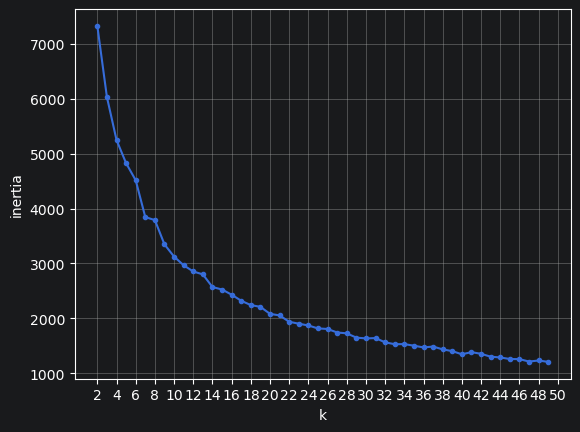

In [588]:
plt.plot(krange, results['inertia'], marker='.')
plt.xticks(np.arange(2, kmax + 2, 2))
plt.ylabel('inertia')
plt.xlabel('k')
plt.grid()
plt.show()
##Misura la somma delle distanze intra-cluster: prendere il gomito

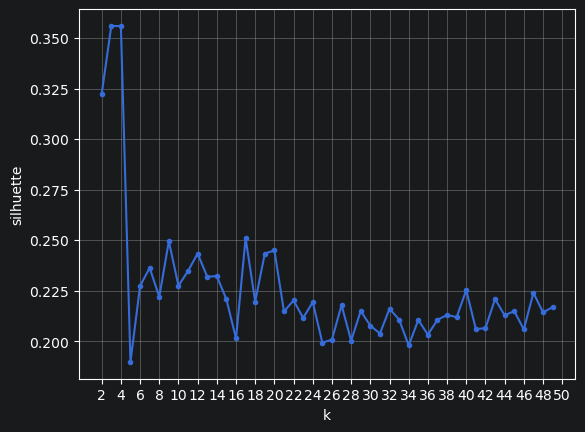

In [589]:
plt.plot(krange, results['silh'], marker='.')
plt.xticks(np.arange(2, kmax + 2, 2))
plt.ylabel('silhuette')
plt.xlabel('k')
plt.grid()
plt.show()
##Range: [-1, 1]
##Più è alto → meglio separati i cluster
##Interpretazione:
##~0.70 → cluster molto buoni
#~0.50 → discreti
#~0.25 → deboli
#<0 → clustering sbagliato

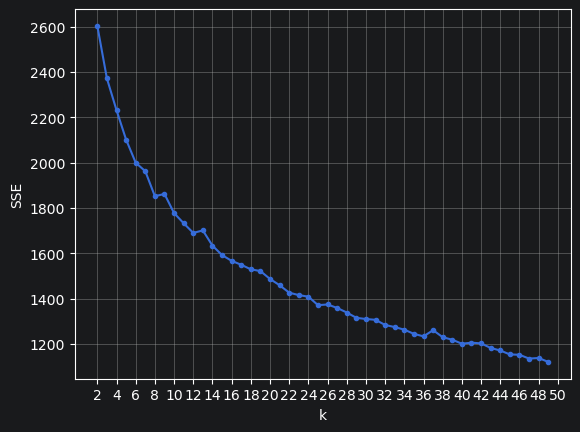

In [590]:
plt.plot(krange, results['sse'], marker='.')
plt.xticks(np.arange(2, kmax + 2, 2))
plt.ylabel('SSE')
plt.xlabel('k')
plt.grid()
plt.show()
# come inertia: prendere il gomiot

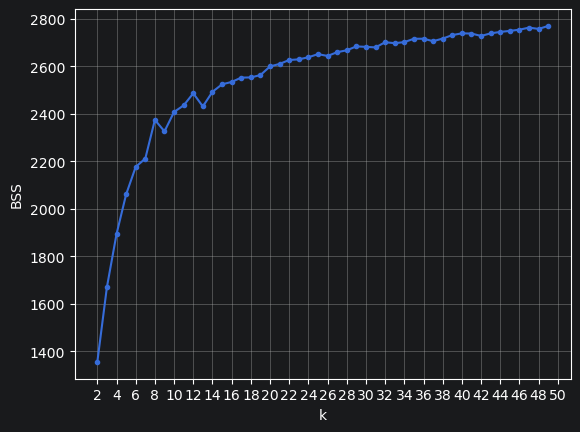

In [591]:
plt.plot(krange, results['bss'], marker='.')
plt.xticks(np.arange(2, kmax + 2, 2))
plt.ylabel('BSS')
plt.xlabel('k')
plt.grid()
plt.show()
###BSS (Between-Cluster Sum of Squares) — ↑ meglio
##Più alto = cluster più separati

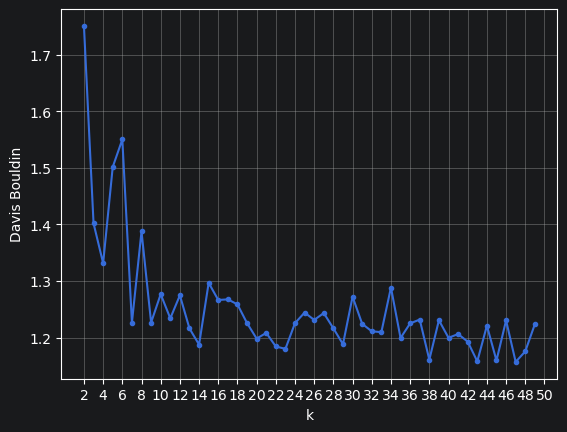

In [592]:
plt.plot(krange, results['davis'], marker='.')
plt.xticks(np.arange(2, kmax + 2, 2))
plt.ylabel('Davis Bouldin')
plt.xlabel('k')
plt.grid()
plt.show()
##Più basso = meglio
#Misura:
#compattezza cluster
#separazione tra cluster

In [593]:
k = 6
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=20
)

kmeans.fit(X)

,n_clusters,6
,init,'k-means++'
,n_init,20
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [594]:
kmeans.fit(X)
clusteringCol = cluster_features
clustering_df['kmeans_label'] = kmeans.labels_

In [595]:
cluster_features

['zona_altimetrica_media',
 'tempo_hub_5000',
 'hub_5000_pop',
 'PAI_POPP3_P4_P',
 'delta_temp',
 'delta_snow',
 'delta_rain']

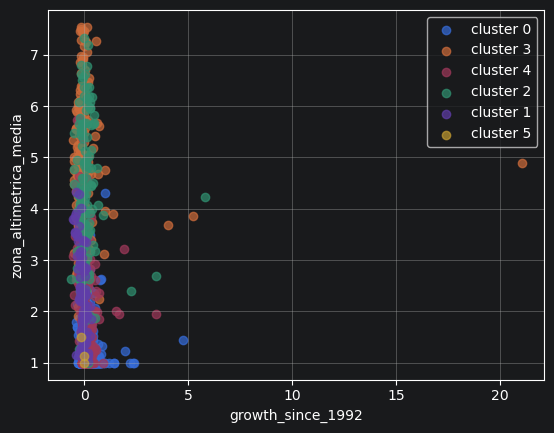

In [596]:
#mostro una 'sezione' di cluster
x = 'growth_since_1992'
y = 'zona_altimetrica_media'

for cluster in clustering_df['kmeans_label'].unique():
    df_analyzed = clustering_df[clustering_df['kmeans_label'] == cluster]
    plt.scatter(df_analyzed[x], df_analyzed[y], label="cluster %s" % cluster, alpha=0.7)

plt.xlabel(x)
#plt.xscale('log')
plt.ylabel(y)
plt.grid()
plt.legend()
plt.show()

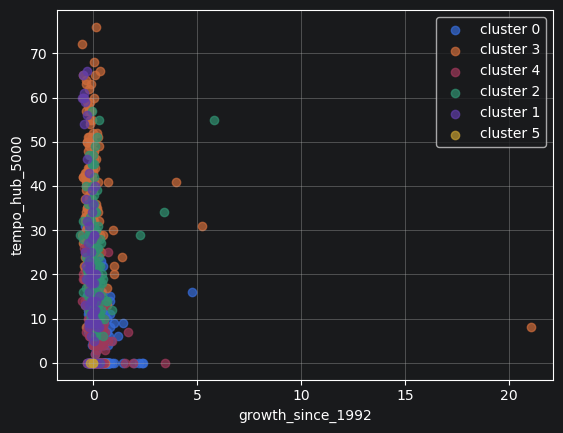

In [597]:
x = 'growth_since_1992'
y = 'tempo_hub_5000'

for cluster in clustering_df['kmeans_label'].unique():
    df_analyzed = clustering_df[clustering_df['kmeans_label'] == cluster]
    plt.scatter(df_analyzed[x], df_analyzed[y], label="cluster %s" % cluster, alpha=0.7)

plt.xlabel(x)
#plt.xscale('log')
plt.ylabel(y)
plt.grid()
plt.legend()
plt.show()

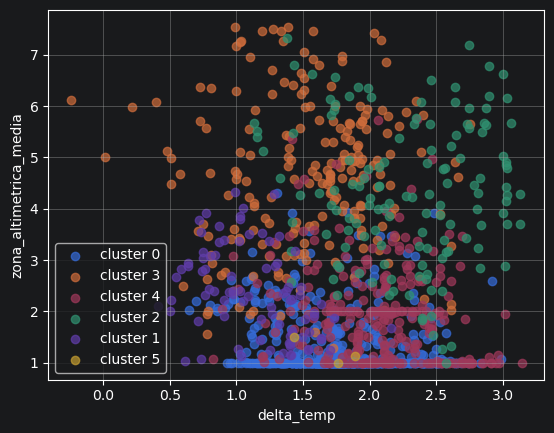

In [598]:
x = 'delta_temp'
y = 'zona_altimetrica_media'

for cluster in clustering_df['kmeans_label'].unique():
    df_analyzed = clustering_df[clustering_df['kmeans_label'] == cluster]
    plt.scatter(df_analyzed[x], df_analyzed[y], label="cluster %s" % cluster, alpha=0.7)

plt.xlabel(x)
#plt.xscale('log')
plt.ylabel(y)
plt.grid()
plt.legend()
plt.show()

In [599]:
cluster_summary = (
    clustering_df.drop(columns=["latitudine", "longitudine"])
    .groupby("kmeans_label")
    .mean(numeric_only=True)
    .round(2)
)

print(cluster_summary)

              growth_since_1992  zona_altimetrica_media  tempo_hub_5000  \
kmeans_label                                                              
0                          0.15                    1.28            5.87   
1                         -0.11                    2.37           18.34   
2                          0.11                    4.31           21.68   
3                          0.06                    4.65           33.28   
4                          0.12                    1.94            6.70   
5                         -0.07                    1.21            0.00   

              hub_5000_pop  PAI_POPP3_P4_P  delta_temp  delta_snow  delta_rain  
kmeans_label                                                                    
0                 12991.33         3358.72        1.77       -1.95        8.62  
1                  8135.49        59024.99        1.14       -1.50       29.50  
2                 20825.83         8899.96        2.29      -11.21       21

In [600]:
clustering_df['kmeans_label'].value_counts()

kmeans_label
0    584
4    280
3    208
2    136
1     85
5      3
Name: count, dtype: int64

In [601]:
clustering_df[clustering_df['kmeans_label']==5]

,comune_norm,Denominazione in italiano,growth_since_1992,latitudine,longitudine,zona_altimetrica_media,tempo_hub_5000,hub_5000_pop,PAI_POPP3_P4_P,delta_temp,delta_snow,delta_rain,kmeans_label
518,GENOVA,Genova,-0.167957,4.920916e+06,491493.460375,1.509144,0.0,564080.0,66361.0,1.433162,-2.580985,28.452273,5
790,PADOVA,Padova,-0.035100,5.031806e+06,725637.544387,1.000000,0.0,207412.0,323.0,1.761029,-0.264091,11.841667,5
1234,VERONA,Verona,-0.002971,5.034741e+06,656563.191142,1.131985,0.0,255039.0,1168.0,1.887401,-2.263864,0.248485,5


# descrizione cluster


Il clustering individua sei gruppi di comuni caratterizzati da differenti condizioni di accessibilità, altitudine, rischio idrogeologico e cambiamento climatico. La variabile **growth_since_1992** non è stata utilizzata per costruire i cluster, ma viene impiegata per descriverne le caratteristiche demografiche.

### Cluster 0 – Comuni di pianura ben accessibili

- Crescita demografica positiva (+15%)
- Altitudine media molto bassa (1.28)
- Tempi di accesso ai poli urbani ridotti (5.9 minuti)
- Poli urbani di dimensione medio-piccola (≈13.000 abitanti)
- Basso rischio idrogeologico
- Incremento moderato della temperatura (+1.77 °C)
- Riduzione limitata delle precipitazioni nevose

Questo cluster rappresenta comuni di pianura o bassa collina con buona accessibilità e condizioni territoriali favorevoli, che mostrano una dinamica demografica positiva.

---

### Cluster 1 – Comuni vulnerabili al rischio idrogeologico

- Crescita demografica negativa (-11%)
- Altitudine intermedia (2.37)
- Accessibilità medio-bassa (18 minuti)
- Poli urbani relativamente piccoli
- Valori molto elevati dell'indicatore PAI
- Incremento delle precipitazioni
- Riduzione moderata della neve

Si tratta di comuni caratterizzati da una maggiore esposizione al rischio idrogeologico e da una lieve perdita di popolazione.

---

### Cluster 2 – Comuni montani soggetti ai maggiori cambiamenti climatici

- Crescita demografica positiva (+11%)
- Altitudine elevata (4.31)
- Accessibilità limitata (22 minuti)
- Poli urbani medi (≈21.000 abitanti)
- Basso rischio idrogeologico
- Maggiore aumento della temperatura (+2.29 °C)
- Forte riduzione delle precipitazioni nevose (-11.21)

Questo gruppo identifica comuni montani nei quali gli effetti del cambiamento climatico risultano particolarmente evidenti.

---

### Cluster 3 – Comuni di alta montagna periferici

- Crescita demografica moderatamente positiva (+6%)
- Altitudine media più elevata (4.65)
- Maggiore distanza dai poli urbani (33 minuti)
- Rischio idrogeologico contenuto
- Cambiamenti climatici meno intensi rispetto al Cluster 2

Questi comuni rappresentano le aree montane più periferiche e meno accessibili del campione.

---

### Cluster 4 – Comuni di pianura interessati dal cambiamento climatico

- Crescita demografica positiva (+12%)
- Altitudine bassa (1.94)
- Buona accessibilità (6.7 minuti)
- Basso rischio idrogeologico
- Forte incremento della temperatura (+2.08 °C)
- Marcato aumento delle precipitazioni

Il cluster comprende comuni relativamente accessibili, nei quali gli effetti climatici risultano particolarmente evidenti pur in presenza di una dinamica demografica favorevole.

---

### Cluster 5 – Grandi poli urbani

- Crescita demografica leggermente negativa (-7%)
- Altitudine molto bassa (1.21)
- Tempo di accesso pari a zero (sono i poli urbani stessi)
- Popolazione del polo molto elevata (≈342.000 abitanti)
- Rischio idrogeologico intermedio
- Cambiamenti climatici moderati

Questo cluster identifica i principali centri urbani del campione, caratterizzati dalla massima accessibilità e da una popolazione molto elevata.

---

## Considerazioni generali

Nel complesso, il clustering evidenzia che la principale distinzione tra i gruppi è determinata da:

- altitudine del territorio;
- accessibilità ai poli urbani;
- esposizione al rischio idrogeologico;
- intensità del cambiamento climatico.



# Plot

In [602]:
clustering_df.columns

Index(['comune_norm', 'Denominazione in italiano', 'growth_since_1992',
       'latitudine', 'longitudine', 'zona_altimetrica_media', 'tempo_hub_5000',
       'hub_5000_pop', 'PAI_POPP3_P4_P', 'delta_temp', 'delta_snow',
       'delta_rain', 'kmeans_label'],
      dtype='object')

In [603]:
from pyproj import Transformer

In [604]:
transformer = Transformer.from_crs(
    "EPSG:25832",   # coordinate originali
    "EPSG:4326",    # lat/lon
    always_xy=True
)

In [605]:
lon, lat = transformer.transform(
    clustering_df["longitudine"].values,
    clustering_df["latitudine"].values
)

clustering_df["lon"] = lon
clustering_df["lat"] = lat

In [606]:
clustering_df[["lat","lon"]].head()

,lat,lon
0,45.358652,11.793246
1,45.897868,9.357889
2,45.056885,12.045257
3,45.556804,10.776728
4,45.175310,11.965383


In [607]:
clustering_df[clustering_df['kmeans_label']==4].head()

,comune_norm,Denominazione in italiano,growth_since_1992,latitudine,longitudine,zona_altimetrica_media,tempo_hub_5000,hub_5000_pop,PAI_POPP3_P4_P,delta_temp,delta_snow,delta_rain,kmeans_label,lon,lat
9,AIRUNO,Airuno,0.123053,5.066921e+06,532771.963193,1.555359,7.0,6332.0,5659.0,1.911106,-3.113712,40.022927,4,9.421378,45.755067
13,ALBAVILLA,Albavilla,0.153361,5.072902e+06,514404.750145,2.593441,0.0,6400.0,6487.0,2.614488,-2.010379,26.507576,4,9.185395,45.809530
15,ALBESE CON CASSANO,Albese con Cassano,0.085409,5.072812e+06,512725.695132,2.591446,4.0,5633.0,6487.0,2.364364,-1.803030,26.508333,4,9.163783,45.808750
18,ALBIOLO,Albiolo,0.458879,5.072453e+06,495487.615501,2.000000,8.0,12111.0,6487.0,1.756626,-1.434470,43.268939,4,8.941928,45.805627
20,ALBISSOLA MARINA,Albissola Marina,-0.131672,4.908928e+06,459576.417896,1.013448,0.0,5157.0,9689.0,1.539471,-4.025530,31.940909,4,8.492963,44.332488


In [608]:
clustering_df[clustering_df['kmeans_label']==3].head()

,comune_norm,Denominazione in italiano,growth_since_1992,latitudine,longitudine,zona_altimetrica_media,tempo_hub_5000,hub_5000_pop,PAI_POPP3_P4_P,delta_temp,delta_snow,delta_rain,kmeans_label,lon,lat
5,AGORDO,Agordo,-0.076092,5.132224e+06,734682.199409,4.577790,25.0,10129.0,2677.0,1.435012,-7.493712,6.693939,3,12.047544,46.302963
12,ALBAREDO PER SAN MARCO,Albaredo per San Marco,-0.396304,5.103137e+06,547937.958486,5.568188,13.0,12358.0,6594.0,1.777511,4.069545,-12.803788,3,9.619991,46.080124
21,ALBOSAGGIA,Albosaggia,-0.028320,5.108391e+06,566406.136828,4.622869,9.0,21331.0,6594.0,2.668007,5.351818,-36.947727,3,9.859555,46.125860
22,ALLEGHE,Alleghe,-0.264368,5.143434e+06,733415.915676,5.708157,42.0,10129.0,2677.0,0.724141,-9.218258,23.945455,3,12.036703,46.404142
27,ALTA VALLE INTELVI,Alta Valle Intelvi,3.998092,5.091343e+06,502817.043819,3.692682,41.0,6225.0,6487.0,1.586035,-2.378939,30.585606,3,9.036365,45.975656


In [609]:
#clustering_df.to_csv("clustering.csv", index=False)

# PLOT

In [610]:
import folium
from folium.plugins import MarkerCluster

In [611]:
# Centro della mappa
m = folium.Map(
    location=[42.5, 12.5],
    zoom_start=6,
    tiles="CartoDB positron"
)

In [612]:
colors = {
    0: "red",
    1: "blue",
    2: "green",
    3: "purple",
    4: "orange",
    5:"lightblue"


}

In [613]:
marker_cluster = MarkerCluster().add_to(m)

for _, row in clustering_df.iterrows():

    if pd.isna(row["lat"]) or pd.isna(row["lon"]):
        continue

    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=5,
        color=colors[row["kmeans_label"]],
        fill=True,
        fill_color=colors[row["kmeans_label"]],
        fill_opacity=0.8,
        popup=f"""
        <b>{row['comune_norm']}</b><br>
        Cluster: {row['kmeans_label']}<br>

        """
    ).add_to(marker_cluster)

m

In [614]:
## opzione 2 per la map
m = folium.Map(
    location=[clustering_df["lat"].mean(), clustering_df["lon"].mean()],
    zoom_start=7
)

for _, row in clustering_df.iterrows():

    if pd.isna(row["lat"]) or pd.isna(row["lon"]):
        continue

    folium.Marker(
        location=[row["lat"], row["lon"]],
        icon=folium.Icon(
        color=colors[row["kmeans_label"]],
        icon="map-marker"
    ),
        popup=f"""
        <b>{row['comune_norm']}</b><br>
        Cluster: {row['kmeans_label']}<br>

        """
    ).add_to(m)

m